# LatentTokenGuard caption benchmark: cloud run

Runs the object-level hallucination benchmark on a cloud GPU.

**Kaggle:** Settings → Accelerator **GPU T4 x2** · Internet **On**. The full run uses both GPUs.
**Colab:** Runtime → GPU (T4 or A100); run the Drive cell so outputs survive disconnects.

The run is resumable: re-running the run cell skips images already captioned in `OUT`.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Settings
`MODEL`: `llava15_7b_4bit` or `llava15_13b` (4-bit) on a 16 GB T4, `llava15_7b` (fp16) on an A100.

In [3]:
import os
MODEL = "llava15_7b_4bit"      # "llava15_13b" for the 13B run; "llava15_7b" on A100
N_IMAGES = 1000                # fixed sample (seed 42), the same on every session
LIMIT = None                   # e.g. 400 to stop after 400 new images in this session
REPO = "https://github.com/sunilsk17/LatentTokenGuard.git"

ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/working")
if not ON_KAGGLE:  # Colab
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = f"/content/drive/MyDrive/ltg_runs/{MODEL}_n{N_IMAGES}_s42"
    WORK = "/content"
else:  # Kaggle: /kaggle/working is saved with the notebook version
    OUT = f"/kaggle/working/{MODEL}_n{N_IMAGES}_s42"
    WORK = "/kaggle/working"
COCO = "/tmp/coco"
print("outputs →", OUT)

Mounted at /content/drive
outputs → /content/drive/MyDrive/ltg_runs/llava15_7b_4bit_n1000_s42


## 2. Code and dependencies

In [4]:
%cd {WORK}
!rm -rf LatentTokenGuard && git clone -q {REPO} LatentTokenGuard
%cd LatentTokenGuard
!git log -1 --oneline
# Do not install requirements.txt here: it pins transformers 4.43 for the old POPE code.
!pip install -q -U bitsandbytes sentencepiece
import transformers, torch; print(transformers.__version__, torch.__version__)

/content
/content/LatentTokenGuard
b311878 (HEAD -> main, origin/main, origin/HEAD) Add caption benchmark for object-level hallucination detection
5.20.2 2.11.0+cu130


## 3. COCO val2017 (≈1 GB, into /tmp so it is not saved as output)

In [5]:
import os
if not os.path.exists(f"{COCO}/val2017"):
    !mkdir -p {COCO}
    !wget -q http://images.cocodataset.org/zips/val2017.zip -O {COCO}/val2017.zip
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -O {COCO}/ann.zip
    !cd {COCO} && unzip -q val2017.zip && unzip -q ann.zip && rm val2017.zip ann.zip
!ls {COCO}/val2017 | wc -l; ls {COCO}/annotations

5000
captions_train2017.json   instances_val2017.json
captions_val2017.json	  person_keypoints_train2017.json
instances_train2017.json  person_keypoints_val2017.json


## 4. Quick timing check (20 images)
Uses the same output folder, so these 20 count towards the run.

In [6]:
!python experiments/caption_run.py --model {MODEL} --n_images {N_IMAGES} --limit 20 \
    --images_dir {COCO}/val2017 --annotations_dir {COCO}/annotations --out {OUT}
import json, numpy as np
recs = [json.loads(l) for l in open(f"{OUT}/captions.jsonl")]
gen = np.mean([r["gen_seconds"] + r["feature_seconds"] for r in recs])
print(f"{len(recs)} images, {gen:.1f} s/image → ~{gen * (N_IMAGES - len(recs)) / 3600:.1f} h for the rest")
print("mean tokens:", np.mean([r["n_tokens"] for r in recs]),
      "| mentions/image:", np.mean([len(r["mentions"]) for r in recs]),
      "| hallucinated share:", np.mean([m["label"] for r in recs for m in r["mentions"]] or [0]))
print(recs[0]["caption"][:400])

2026-10-26 18:46:49,816 [INFO] 1000 images sampled, 0 done, 20 to go
2026-10-26 18:47:01,636 [INFO] NumExpr defaulting to 2 threads.
2026-10-26 18:47:02,151 [INFO] Loading llava-hf/llava-1.5-7b-hf on cuda (dtype=torch.float16, 4bit=True)
2026-10-26 18:47:02,287 [INFO] HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-10-26 18:47:02,378 [INFO] HTTP Request: GET https://huggingface.co/api/models/llava-hf/llava-1.5-7b-hf "HTTP/1.1 200 OK"
2026-10-26 18:47:02,469 [INFO] HTTP Request: HEAD https://huggingface.co/llava-hf/llava-1.5-7b-hf/resolve/b234b804b114d9e37bb655e11cbbb5f5e971b7a9/processor_config.json "HTTP/1.1 307 Temporary Redirect"
2026-10-26 18:47:02,481 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/llava-hf/llava-1.5-7b-hf/b234b804b114d9e37bb655e11cbbb5f5e971b7a9/processor_config.json?%2Fllava-hf%2Fllava-1.5-7b-hf%2Fresolve%2Fb234b804b114d9e37bb655e11cbbb5f5e971b7a9%2Fprocessor_config.json=&etag=%22af0ccfc7718788d1bdd1b

## 5. Full run (resumable)
With several GPUs (Kaggle T4 x2), one process runs per GPU and each captions every N-th image. The first process loads the model before the others start, so the weights download once. The shard files are merged into `captions.jsonl` at the end.

In [ ]:
import glob, subprocess, time, torch

n_gpu = max(torch.cuda.device_count(), 1)
limit = f"--limit {LIMIT}" if LIMIT else ""
cmd = (f"python experiments/caption_run.py --model {MODEL} --n_images {N_IMAGES} {limit} "
       f"--images_dir {COCO}/val2017 --annotations_dir {COCO}/annotations --out {OUT}")

def started(log):
    return os.path.exists(log) and "Captioning" in open(log, errors="ignore").read()

if n_gpu == 1:
    !{cmd}
else:
    procs = []
    for k in range(n_gpu):
        log = f"{WORK}/shard{k}.log"
        env = {**os.environ, "CUDA_VISIBLE_DEVICES": str(k)}
        procs.append(subprocess.Popen(f"{cmd} --shard {k}/{n_gpu} > {log} 2>&1", shell=True, env=env))
        while k == 0 and procs[0].poll() is None and not started(log):
            time.sleep(20)
    while any(p.poll() is None for p in procs):
        time.sleep(300)
        done = sum(sum(1 for _ in open(f)) for f in glob.glob(f"{OUT}/captions*.jsonl"))
        print(time.strftime("%H:%M"), f"{done}/{N_IMAGES} images captioned", flush=True)
    for k, p in enumerate(procs):
        print(f"shard {k}: exit code {p.returncode}")
        !tail -c 600 {WORK}/shard{k}.log
    !python experiments/caption_run.py --merge --out {OUT}
!wc -l {OUT}/captions.jsonl

## 6. Evaluate

# Object hallucination detection: llava-hf/llava-1.5-7b-hf

Images: 1000 (calib 500, test 500). Object mentions: 3281 (837 hallucinated). Test: 1632 mentions, 419 hallucinated.

CHAIR on test captions: CHAIR_i 25.7, CHAIR_s 46.8

| Detector | AUROC [95% CI] | AUPR [95% CI] | Selected on calib | CHAIR_i after removal | Real objects kept |
|---|---|---|---|---|---|
| NLL | 74.6 [71.8, 76.9] | 49.9 [44.7, 55.5] | – | 20.8 | 93.6% |
| Entropy | 75.2 [72.6, 77.8] | 50.1 [45.4, 54.9] | – | 22.5 | 95.6% |
| Internal Confidence (max over layers) | 75.5 [72.7, 78.3] | 52.9 [48.0, 58.9] | – | 20.6 | 93.9% |
| Internal Confidence (calib layer) | 78.6 [76.1, 81.1] | 56.9 [51.6, 62.2] | layer=32 | 19.8 | 94.2% |
| Max-patch cosine, same layer (LTG/ContextualLens) | 87.0 [85.0, 88.9] | 68.9 [63.7, 74.2] | position=at, text_layer=24, image_layer=24, stat=max, sign=- | 16.2 | 95.1% |
| Max-patch cosine, layer pair | 87.0 [85.0, 88.9] | 68.9 [63.7, 74.2] | position=at, text_layer=24, image_layer=24, st

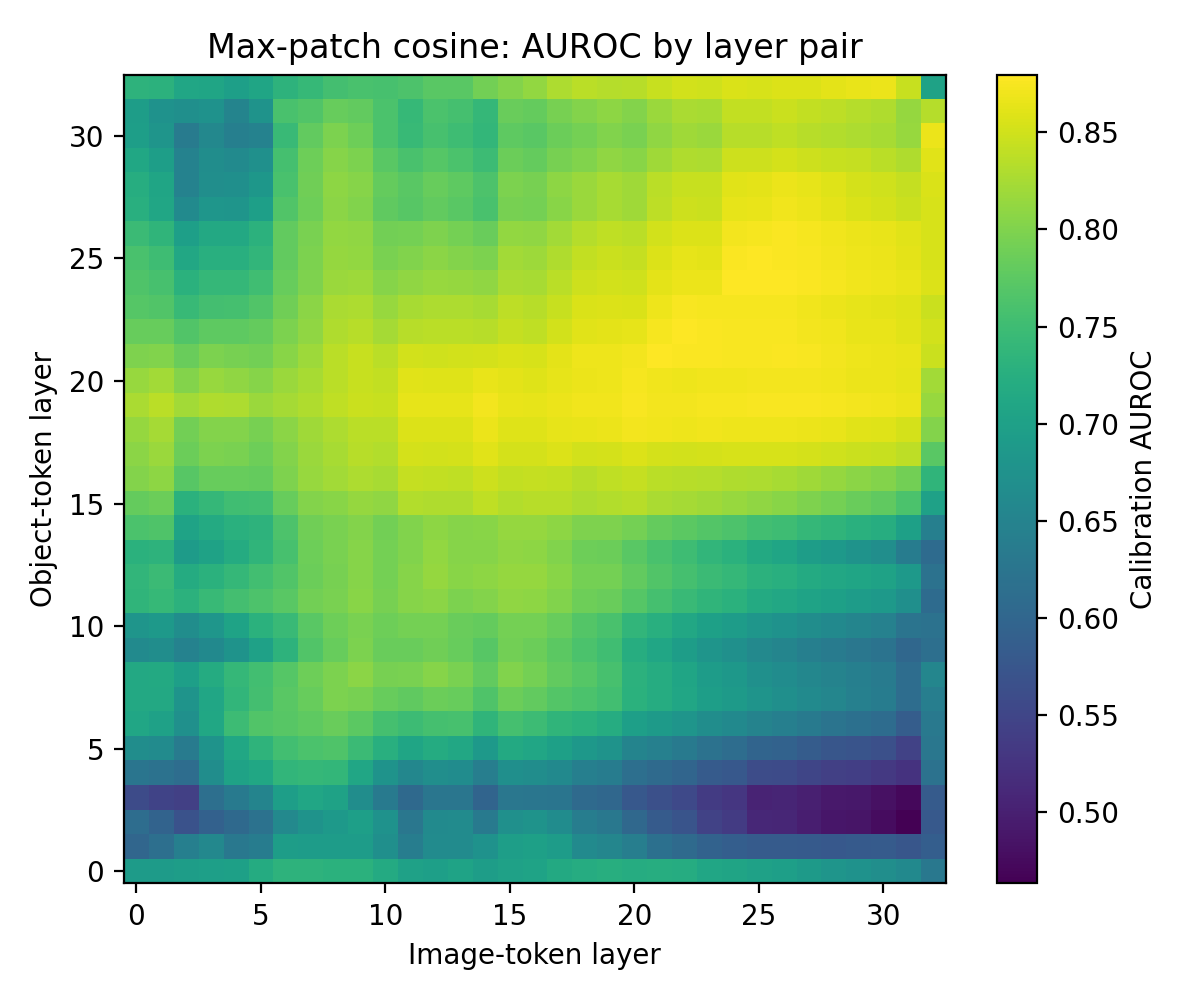

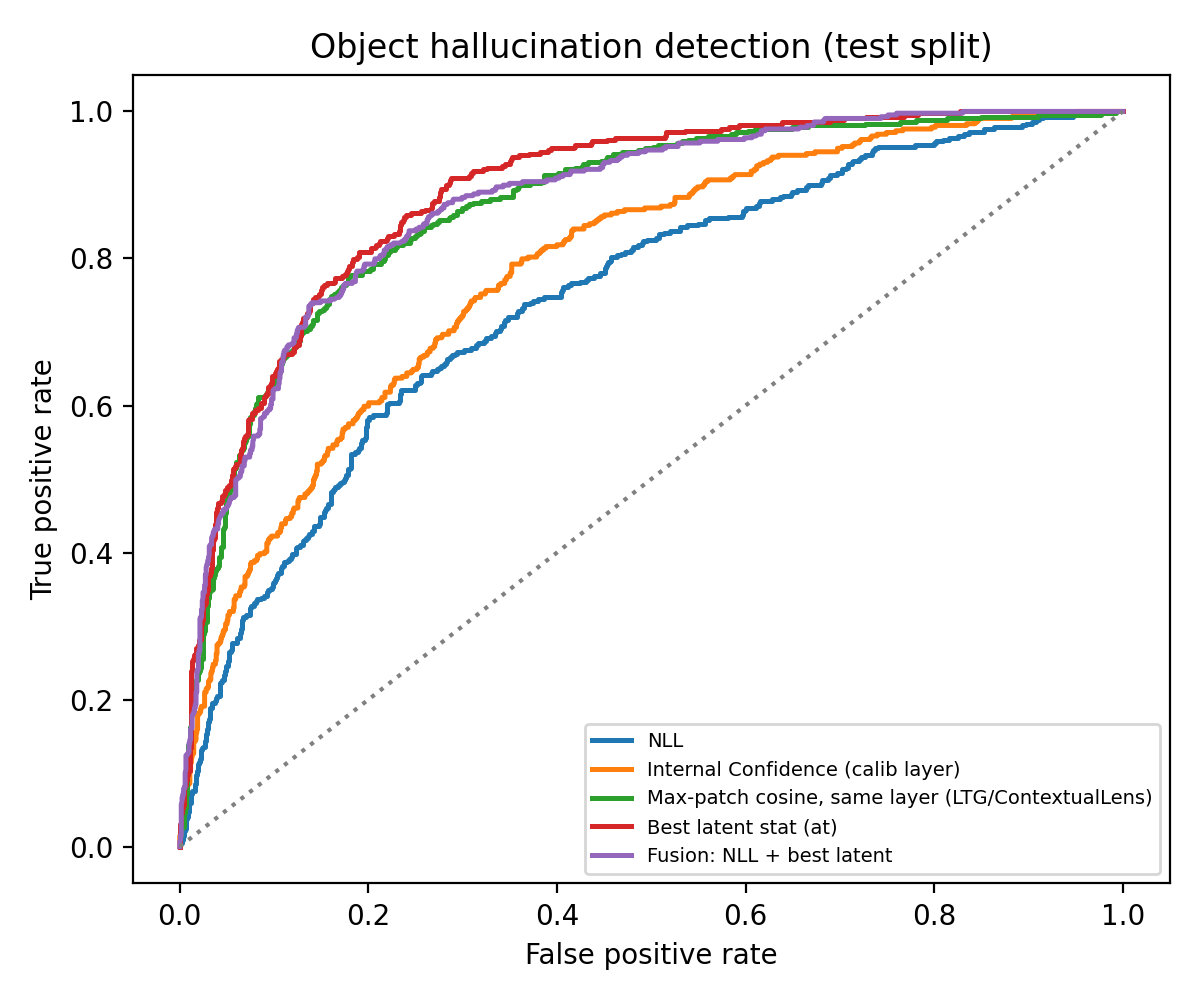

In [8]:
!python experiments/caption_eval.py --run {OUT}
from IPython.display import Image, display
display(Image(f"{OUT}/eval/layer_map.png")); display(Image(f"{OUT}/eval/roc_test.png"))

## 7. Save the run
Kaggle: **Save Version → Save & Run All** keeps `/kaggle/working`. To resume in a new session, attach that
version's output as an input dataset and copy the run folder back to `OUT` before step 5.
Colab: the run is already on Drive.

Zip it to download for local evaluation:

In [9]:
!cd {os.path.dirname(OUT)} && zip -qr {os.path.basename(OUT)}.zip {os.path.basename(OUT)} && ls -lh {os.path.basename(OUT)}.zip

-rw------- 1 root root 423M Oct 26 20:54 llava15_7b_4bit_n1000_s42.zip
